In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import HistGradientBoostingClassifier


# Cardiovascular Disease Prediction

### Machine Learning Classification with Clinical and Lifestyle Data

This project develops and evaluates machine learning models for predicting the presence of cardiovascular disease using demographic, clinical, and lifestyle features.

**Models explored:** Logistic Regression, Random Forest, and HistGradientBoosting

**Tools:** Python, Pandas, NumPy, Scikit-learn, Matplotlib, Seaborn


## 1. Project Overview

Cardiovascular disease is influenced by a combination of demographic, physiological, and lifestyle factors. The goal of this project is to investigate whether machine learning models can use these characteristics to predict whether a patient has cardiovascular disease.

The analysis follows a complete machine learning workflow:

1. Load and explore the dataset
2. Clean implausible measurements
3. Engineer additional features
4. Split the data into training and testing sets
5. Train baseline classification models
6. Evaluate model performance using multiple metrics
7. Analyze feature importance
8. Reduce and refine the feature set
9. Tune model hyperparameters
10. Compare final model performance


## 2. Data Loading

The dataset contains **70,000 patient observations** and 13 variables describing demographic characteristics, physical measurements, cardiovascular indicators, lifestyle factors, and the target variable.

The target variable, `cardio`, indicates whether cardiovascular disease is present:

* `0` — No cardiovascular disease
* `1` — Cardiovascular disease


In [2]:
df = pd.read_csv("cardio_train.csv", sep=";")

df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [3]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isna().sum())

print("\nTarget distribution:")
print(df["cardio"].value_counts())

Shape: (70000, 13)

Columns:
['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']

Missing values:
id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64

Target distribution:
cardio
0    35021
1    34979
Name: count, dtype: int64


## 3. Exploratory Data Analysis

Before training any models, I examined the dataset's dimensions, variables, missing values, and target distribution.

The dataset contains 70,000 observations with no missing values. The target variable is also approximately balanced between the two classes, making accuracy a useful metric while still motivating the use of precision, recall, F1 score, and ROC-AUC for a more complete evaluation.
(The EDA code is in "EDA.py")

## 4. Data Cleaning & Feature Engineering

Several preprocessing steps were performed before modeling.

### Feature Engineering

Three additional features were created:

* **Age in years:** converted the original age measurement from days to years
* **BMI:** calculated from weight and height
* **Blood pressure difference:** calculated as systolic blood pressure minus diastolic blood pressure

The original `id` column was removed because it does not contain meaningful predictive information, and the original age-in-days column was replaced by the more interpretable `age_years` feature.

### Data Cleaning

Implausible measurements for height, weight, systolic blood pressure, and diastolic blood pressure were removed using reasonable physiological bounds.


In [4]:
#copying the dataset
data = df.copy()

# converting age from days to years for more readability
data["age_years"] = data["age"] / 365.25

# adding a body mass index column
data["bmi"] = data["weight"] / (data["height"] / 100) ** 2

# Adding a pulse difference column
data["bp_difference"] = data["ap_hi"] - data["ap_lo"]

#removing redundant columns
data = data.drop(columns=["id", "age"])
data.head()

,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,bmi,bp_difference
0,2,168,62.0,110,80,1,1,0,0,1,0,50.357290,21.967120,30
1,1,156,85.0,140,90,3,1,0,0,1,1,55.381246,34.927679,50
2,1,165,64.0,130,70,3,1,0,0,0,1,51.627652,23.507805,60
3,2,169,82.0,150,100,1,1,0,0,1,1,48.249144,28.710479,50
4,1,156,56.0,100,60,1,1,0,0,0,0,47.841205,23.011177,40


In [5]:
#getting rid of implausible measurements
data = data[
    (data["height"] >= 120) & (data["height"] <= 220) &
    (data["weight"] >= 30) & (data["weight"] <= 200) &
    (data["ap_hi"] >= 70) & (data["ap_hi"] <= 240) &
    (data["ap_lo"] >= 40) & (data["ap_lo"] <= 160)
]

## 5. Preparing the Data for Machine Learning

The target variable is `cardio`, while all remaining variables are used as candidate predictors.

The cleaned dataset contains **68,706 observations** after removing implausible measurements.

The data was divided into:

* **80% training data**
* **20% testing data**

A fixed `random_state=42` was used for reproducibility, and stratification was applied to preserve the proportion of cardiovascular-disease cases in both subsets.


In [6]:
#ML Setup:
X = data.drop(columns=["cardio"])
y = data["cardio"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y) #stratify ensures proportionality between CVD/No CVD is consistent among test/train

In [7]:
#check cell for assurance


# print("X shape:", X.shape)
# print("y shape:", y.shape)
print("Training:", X_train.shape)
print("Testing:", X_test.shape)


Training: (54964, 13)
Testing: (13742, 13)


## 6. Baseline Models

### 6.1 Logistic Regression

Logistic Regression provides a simple and interpretable baseline for binary classification. It models the probability of cardiovascular disease as a function of the input features.

Performance is evaluated using:

* **Accuracy** — overall proportion of correct predictions
* **Precision** — proportion of predicted positive cases that are actually positive
* **Recall** — proportion of actual positive cases identified by the model
* **F1 Score** — harmonic mean of precision and recall
* **ROC-AUC** — ability to distinguish between the two classes across classification thresholds


In [8]:
#Logistic model creation
logistic_model = Pipeline([("model", LogisticRegression(max_iter=1000))])
logistic_model.fit(X_train, y_train)

logistic_pred = logistic_model.predict(X_test) #binary classifier, 0 or 1 for noCVD or CVD
logistic_prob = logistic_model.predict_proba(X_test)[:, 1] #probabilities, if calculated 0 or 1, this tells us why

C:\Users\moham\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [9]:
#Logistic regression stats
print("Logistic Regression\n")
print("Accuracy:", accuracy_score(y_test, logistic_pred))
print("Precision:", precision_score(y_test, logistic_pred))
print("Recall:", recall_score(y_test, logistic_pred))
print("F1:", f1_score(y_test, logistic_pred))
print("ROC-AUC:", roc_auc_score(y_test, logistic_prob))

Logistic Regression

Accuracy: 0.7236937854751856
Precision: 0.7495429616087751
Recall: 0.663235294117647
F1: 0.7037528282749473
ROC-AUC: 0.7888380404019861


### 6.2 Random Forest

Random Forest is an ensemble learning method that combines many decision trees. Unlike Logistic Regression, it can capture nonlinear relationships and interactions between features without requiring those relationships to be specified manually.

This provides a useful comparison between a linear classification model and a nonlinear tree-based approach.


In [10]:
#Random Forest Classifier:
rf_model = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

In [11]:
#Random Forest stats:
print("Random Forest\n")
print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1:", f1_score(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))

Random Forest

Accuracy: 0.7112501819240286
Precision: 0.7142208774583964
Recall: 0.6942647058823529
F1: 0.7041014168530947
ROC-AUC: 0.7746674547087634


## 7. Baseline Model Evaluation

The initial models provide a benchmark for evaluating whether feature engineering, feature selection, and hyperparameter tuning improve predictive performance.

The models are compared using accuracy, precision, recall, F1 score, and ROC-AUC rather than relying on a single metric.


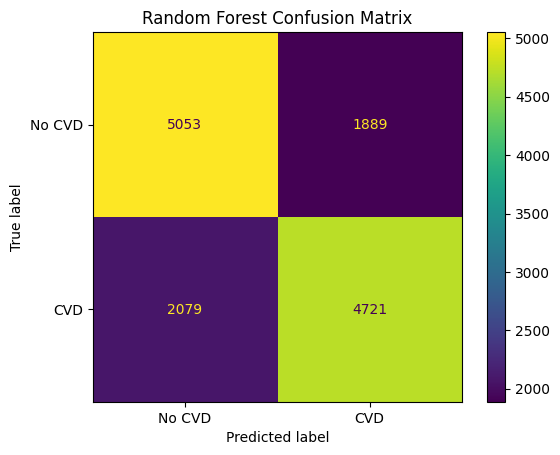

In [12]:
#Random Forest confusion matrix:
cm = confusion_matrix(y_test, rf_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No CVD", "CVD"])
disp.plot()
plt.title("Random Forest Confusion Matrix")
plt.show()

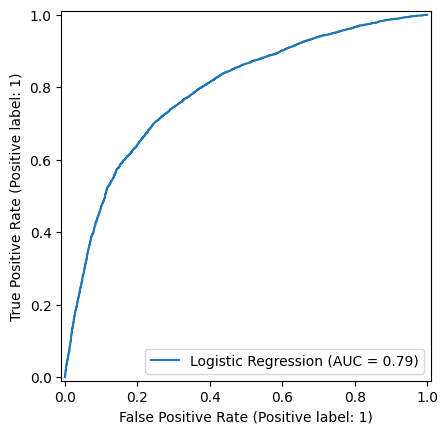

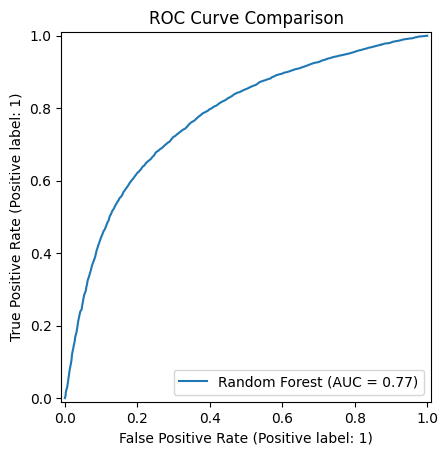

In [13]:
#ROC visualization
RocCurveDisplay.from_predictions(y_test, logistic_prob, name="Logistic Regression")

RocCurveDisplay.from_predictions(y_test, rf_prob, name="Random Forest")

plt.title("ROC Curve Comparison")
plt.show()

## Model Evaluation

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | **72.37%** | **74.95%** | 66.32% | 70.38% | **0.789** |
| Random Forest | 71.13% | 71.42% | **69.43%** | **70.41%** | 0.775 |

Logistic Regression achieved **72.4% accuracy** and a **ROC-AUC of 0.789**, while Random Forest achieved **71.1% accuracy** and a **ROC-AUC of 0.775**.

Random Forest achieved slightly higher **recall (69.4% vs. 66.3%)**, identifying a larger proportion of patients with cardiovascular disease. Logistic Regression produced higher **precision (75.0% vs. 71.4%)**, meaning a larger proportion of its positive predictions were correct.

Both models achieved an **F1 score of approximately 0.70**, indicating similar overall balance between precision and recall.

## 8. Feature Importance & Interpretation

Understanding which variables contribute most to model predictions can provide insight into the relationships captured by the machine learning models.

Random Forest's built-in feature importance is examined first. Because correlated features can distribute importance across multiple variables, these results should be interpreted cautiously rather than treating importance values as independent measures of predictive contribution.


age_years        0.258165
bmi              0.158475
ap_hi            0.117329
weight           0.116748
height           0.110923
ap_lo            0.071093
bp_difference    0.066709
cholesterol      0.036947
gender           0.016762
gluc             0.016746
active           0.013736
smoke            0.009121
alco             0.007246
dtype: float64


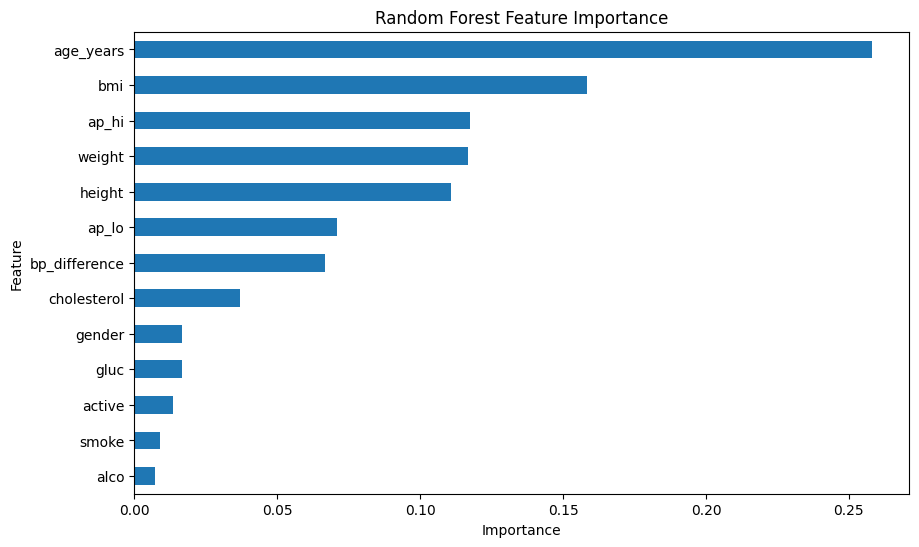

In [14]:
#Which features did our initial rf model use
rf_importance = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

print(rf_importance)
#important note: a large percentage comes from redundant features, bmi, height, and weight are all connected we don't need all three etc.
plt.figure(figsize=(10, 6))
rf_importance.sort_values().plot(kind="barh")

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

In [15]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="roc_auc",
    n_jobs=-1
)

perm_importance = pd.Series(
    perm.importances_mean,
    index=X_test.columns
).sort_values(ascending=False)

print(perm_importance)

#Feature Interpretation: Random Forest permutation importance identified systolic blood pressure (ap_hi) as the most influential 
#predictor, followed by age and cholesterol. While the model's built-in impurity-based feature importance assigned substantial
#importance to BMI, height, and weight, permutation testing suggested these features contributed little unique predictive 
#information after accounting for correlated variables. This illustrates the importance of considering feature correlation when 
#interpreting tree-based feature importance.



ap_hi            0.093155
age_years        0.031173
cholesterol      0.030726
ap_lo            0.004647
active           0.002652
gluc             0.002241
bp_difference    0.002047
gender           0.000505
smoke            0.000405
alco             0.000355
bmi             -0.008681
weight          -0.009737
height          -0.010609
dtype: float64


In [16]:
#finding the feature coefficients for our logistics regression model:
logistic_coefficients = pd.Series(logistic_model.named_steps["model"].coef_[0], index=X_train.columns).sort_values()

print(logistic_coefficients)
odds_ratios = np.exp(logistic_coefficients)

print(odds_ratios.sort_values(ascending=False))

active          -0.198576
gluc            -0.132861
alco            -0.122695
smoke           -0.072688
gender          -0.062112
bmi             -0.029445
height          -0.014537
bp_difference    0.012000
weight           0.022386
ap_lo            0.028887
ap_hi            0.040887
age_years        0.051814
cholesterol      0.499544
dtype: float64
cholesterol      1.647970
age_years        1.053180
ap_hi            1.041734
ap_lo            1.029308
weight           1.022638
bp_difference    1.012073
height           0.985568
bmi              0.970985
gender           0.939778
smoke            0.929891
alco             0.884533
gluc             0.875586
active           0.819898
dtype: float64


## 9. Feature Selection

The initial feature-importance analysis suggested that several variables contained overlapping information. In particular, height, weight, and BMI are mathematically related.

A reduced feature set was therefore created to investigate whether removing potentially redundant variables could maintain or improve predictive performance while producing a simpler model.


In [17]:
#New model post feature-engineering:
reduced_features = [
    "age_years",
    "bmi",
    "ap_hi",
    "ap_lo",
    "cholesterol",
    "gluc",
    "smoke",
    "alco",
    "active",
    "gender"
]

X_reduced = data[reduced_features]
y = data["cardio"]
X_train_red, X_test_red, y_train_red, y_test_red = train_test_split(
    X_reduced,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [18]:
#New logistic reg model:
logistic_reduced = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

logistic_reduced.fit(X_train_red, y_train_red)

logistic_red_pred = logistic_reduced.predict(X_test_red)
logistic_red_prob = logistic_reduced.predict_proba(X_test_red)[:, 1]
print("Reduced Logistic Regression")
print("Accuracy:", accuracy_score(y_test_red, logistic_red_pred))
print("Precision:", precision_score(y_test_red, logistic_red_pred))
print("Recall:", recall_score(y_test_red, logistic_red_pred))
print("F1:", f1_score(y_test_red, logistic_red_pred))
print("ROC-AUC:", roc_auc_score(y_test_red, logistic_red_prob))

Reduced Logistic Regression
Accuracy: 0.7243487119778781
Precision: 0.7502492522432702
Recall: 0.6639705882352941
F1: 0.7044780777032298
ROC-AUC: 0.7890406646669039


In [19]:
#New Random Forest model:
rf_reduced = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_reduced.fit(X_train_red, y_train_red)

rf_red_pred = rf_reduced.predict(X_test_red)
rf_red_prob = rf_reduced.predict_proba(X_test_red)[:, 1]
print("Reduced Random Forest")
print("Accuracy:", accuracy_score(y_test_red, rf_red_pred))
print("Precision:", precision_score(y_test_red, rf_red_pred))
print("Recall:", recall_score(y_test_red, rf_red_pred))
print("F1:", f1_score(y_test_red, rf_red_pred))
print("ROC-AUC:", roc_auc_score(y_test_red, rf_red_prob))

Reduced Random Forest
Accuracy: 0.707684470964925
Precision: 0.7097211755840241
Recall: 0.6925
F1: 0.7010048381094157
ROC-AUC: 0.7654617460640263


### 9.1 Comparing the Reduced Feature Set

The reduced models are compared against their original counterparts to determine whether removing potentially redundant features improves predictive performance.

This comparison helps distinguish between features that provide useful predictive information and features whose information may already be captured by other variables.


In [20]:
#Compare all four models:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Reduced Logistic Regression",
        "Random Forest",
        "Reduced Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, logistic_pred),
        accuracy_score(y_test_red, logistic_red_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test_red, rf_red_pred)
    ],
    "Precision": [
        precision_score(y_test, logistic_pred),
        precision_score(y_test_red, logistic_red_pred),
        precision_score(y_test, rf_pred),
        precision_score(y_test_red, rf_red_pred)
    ],
    "Recall": [
        recall_score(y_test, logistic_pred),
        recall_score(y_test_red, logistic_red_pred),
        recall_score(y_test, rf_pred),
        recall_score(y_test_red, rf_red_pred)
    ],
    "F1": [
        f1_score(y_test, logistic_pred),
        f1_score(y_test_red, logistic_red_pred),
        f1_score(y_test, rf_pred),
        f1_score(y_test_red, rf_red_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, logistic_prob),
        roc_auc_score(y_test_red, logistic_red_prob),
        roc_auc_score(y_test, rf_prob),
        roc_auc_score(y_test_red, rf_red_prob)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.723694,0.749543,0.663235,0.703753,0.788838
1,Reduced Logistic Regression,0.724349,0.750249,0.663971,0.704478,0.789041
2,Random Forest,0.711250,0.714221,0.694265,0.704101,0.774667
3,Reduced Random Forest,0.707684,0.709721,0.692500,0.701005,0.765462


## 10. Hyperparameter Tuning

After establishing baseline performance, hyperparameter tuning was performed to investigate whether model performance could be improved by adjusting model configuration.

`GridSearchCV` was used to systematically evaluate combinations of hyperparameters using cross-validation on the training data.

The test set was reserved for final evaluation so that it could provide an unbiased estimate of performance on unseen data.


In [21]:
#Tuning the regularization of the logistic regression model
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

lr_params = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

lr_grid = GridSearchCV(
    lr_pipeline,
    lr_params,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

lr_grid.fit(X_train_red, y_train_red)

print("Best parameters:", lr_grid.best_params_)
print("Best CV ROC-AUC:", lr_grid.best_score_)
best_lr = lr_grid.best_estimator_

lr_tuned_pred = best_lr.predict(X_test_red)
lr_tuned_prob = best_lr.predict_proba(X_test_red)[:, 1]

Best parameters: {'model__C': 100}
Best CV ROC-AUC: 0.7906576570968646


In [22]:
print("Tuned Logistic Regression")
print("Accuracy:", accuracy_score(y_test_red, lr_tuned_pred))
print("Precision:", precision_score(y_test_red, lr_tuned_pred))
print("Recall:", recall_score(y_test_red, lr_tuned_pred))
print("F1:", f1_score(y_test_red, lr_tuned_pred))
print("ROC-AUC:", roc_auc_score(y_test_red, lr_tuned_prob))

Tuned Logistic Regression
Accuracy: 0.7244214815892883
Precision: 0.7502907459710916
Recall: 0.6641176470588235
F1: 0.70457914033856
ROC-AUC: 0.7890404528276306


In [23]:
#Tuning random forest:
rf_params = {
    "n_estimators": [300, 500],
    "max_depth": [None, 10, 20, 30],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    rf_params,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

rf_grid.fit(X_train_red, y_train_red)

print("Best parameters:", rf_grid.best_params_)
print("Best CV ROC-AUC:", rf_grid.best_score_)
best_rf = rf_grid.best_estimator_

rf_tuned_pred = best_rf.predict(X_test_red)
rf_tuned_prob = best_rf.predict_proba(X_test_red)[:, 1]


Best parameters: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'n_estimators': 500}
Best CV ROC-AUC: 0.8004321028941848


In [24]:
print("Tuned Random Forest")
print("Accuracy:", accuracy_score(y_test_red, rf_tuned_pred))
print("Precision:", precision_score(y_test_red, rf_tuned_pred))
print("Recall:", recall_score(y_test_red, rf_tuned_pred))
print("F1:", f1_score(y_test_red, rf_tuned_pred))
print("ROC-AUC:", roc_auc_score(y_test_red, rf_tuned_prob))
#notes: major increase in ROC-AUC! Interesting that max depth = 10 helped

Tuned Random Forest
Accuracy: 0.7346092271867268
Precision: 0.7613127797115863
Recall: 0.6754411764705882
F1: 0.7158108002805268
ROC-AUC: 0.8012790431643704


In [25]:
#new features test:
data_fe = data.copy()

data_fe["age_squared"] = data_fe["age_years"] ** 2
data_fe["bmi_squared"] = data_fe["bmi"] ** 2
data_fe["age_ap_hi"] = data_fe["age_years"] * data_fe["ap_hi"]
data_fe["age_cholesterol"] = data_fe["age_years"] * data_fe["cholesterol"]
features_fe = [
    "age_years",
    "bmi",
    "ap_hi",
    "ap_lo",
    "cholesterol",
    "gluc",
    "smoke",
    "alco",
    "active",
    "gender",
    "age_squared",
    "bmi_squared",
    "age_ap_hi",
    "age_cholesterol"
]

X_fe = data_fe[features_fe]
y_fe = data_fe["cardio"]

In [26]:
#new feature ml:
X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    X_fe,
    y_fe,
    test_size=0.20,
    random_state=42,
    stratify=y_fe
)
#use our new tuning parameters!
rf_fe = RandomForestClassifier(
    n_estimators=500,
    max_depth=10,
    max_features="sqrt",
    min_samples_leaf=4,
    random_state=42,
    n_jobs=-1
)

rf_fe.fit(X_train_fe, y_train_fe)
rf_fe_pred = rf_fe.predict(X_test_fe)
rf_fe_prob = rf_fe.predict_proba(X_test_fe)[:, 1]


In [27]:
print("Feature-Engineered Random Forest")
print("Accuracy:", accuracy_score(y_test_fe, rf_fe_pred))
print("Precision:", precision_score(y_test_fe, rf_fe_pred))
print("Recall:", recall_score(y_test_fe, rf_fe_pred))
print("F1:", f1_score(y_test_fe, rf_fe_pred))
print("ROC-AUC:", roc_auc_score(y_test_fe, rf_fe_prob))
#notes: didn't work, little to no increase :(

Feature-Engineered Random Forest
Accuracy: 0.7330082957357008
Precision: 0.7555084054186388
Recall: 0.6807352941176471
F1: 0.7161754467393827
ROC-AUC: 0.8003049850017795


## 11. HistGradientBoosting

HistGradientBoosting is a gradient-boosted decision-tree method designed to efficiently model nonlinear relationships.

It was evaluated alongside Logistic Regression and Random Forest to determine whether gradient boosting could capture additional predictive structure in the cardiovascular disease dataset.


In [28]:
hgb = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=31,
    random_state=42
)

hgb.fit(X_train_red, y_train_red)

,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.05
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",300
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""Categorical"" and ""Enum"" are considered to be categorical features. The input must be a dataframe that is supported by narwhals (or supports it): :func:`narwhals.from_native` must work. This is the case, for instance, for pandas and polars DataFrames.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing va

In [29]:
hgb_pred = hgb.predict(X_test_red)
hgb_prob = hgb.predict_proba(X_test_red)[:, 1]

print("HistGradientBoosting")
print("Accuracy:", accuracy_score(y_test_red, hgb_pred))
print("Precision:", precision_score(y_test_red, hgb_pred))
print("Recall:", recall_score(y_test_red, hgb_pred))
print("F1:", f1_score(y_test_red, hgb_pred))
print("ROC-AUC:", roc_auc_score(y_test_red, hgb_prob))
#notes: great news, a new #1, now let's tune it...

HistGradientBoosting
Accuracy: 0.7332993741813418
Precision: 0.7545882735098263
Recall: 0.683235294117647
F1: 0.7171413135756733
ROC-AUC: 0.8018369960343688


In [30]:
#Gradient Boosting Tuning:
hgb_params = {
    "learning_rate": [0.03, 0.05, 0.1],
    "max_iter": [200, 300, 500],
    "max_leaf_nodes": [15, 31, 63],
    "min_samples_leaf": [20, 50],
    "l2_regularization": [0, 1]
}

hgb_grid = GridSearchCV(
    HistGradientBoostingClassifier(
        random_state=42
    ),
    hgb_params,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

hgb_grid.fit(X_train_red, y_train_red)

print("Best parameters:", hgb_grid.best_params_)
print("Best CV ROC-AUC:", hgb_grid.best_score_)

Best parameters: {'l2_regularization': 1, 'learning_rate': 0.1, 'max_iter': 200, 'max_leaf_nodes': 15, 'min_samples_leaf': 50}
Best CV ROC-AUC: 0.8012391313948642


In [33]:
#test out the tuned gradient boost similarly to everything else:
best_hgb = hgb_grid.best_estimator_

hgb_tuned_pred = best_hgb.predict(X_test_red)
hgb_tuned_prob = best_hgb.predict_proba(X_test_red)[:, 1]

print("Tuned HistGradientBoosting")
print("Accuracy:", accuracy_score(y_test_red, hgb_tuned_pred))
print("Precision:", precision_score(y_test_red, hgb_tuned_pred))
print("Recall:", recall_score(y_test_red, hgb_tuned_pred))
print("F1:", f1_score(y_test_red, hgb_tuned_pred))
print("ROC-AUC:", roc_auc_score(y_test_red, hgb_tuned_prob))


Tuned HistGradientBoosting
Accuracy: 0.7324261388444185
Precision: 0.7514897729102915
Recall: 0.6861764705882353
F1: 0.7173495272503652
ROC-AUC: 0.8017237785347501


## 12. Final Model Comparison

The final models are compared using five evaluation metrics:

| Metric        | Description                                                       |
| ------------- | ----------------------------------------------------------------- |
| **Accuracy**  | Overall proportion of correct predictions                         |
| **Precision** | Proportion of predicted positive cases that are actually positive |
| **Recall**    | Proportion of actual positive cases identified                    |
| **F1 Score**  | Balance between precision and recall                              |
| **ROC-AUC**   | Overall discrimination between positive and negative classes      |

Using multiple metrics provides a more complete view of model behavior, particularly because improving recall can sometimes come at the expense of precision.


| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | 72.37% | 74.95% | 66.32% | 70.38% | 0.7890 |
| Tuned Logistic Regression | 72.44% | 75.03% | 66.41% | 70.46% | 0.7890 |
| Tuned Random Forest | 73.46% | 76.13% | 67.54% | 71.58% | 0.8013 |
| HistGradientBoosting | 73.33% | 75.46% | 68.32% | 71.71% | 0.8018 |
| Tuned HistGradientBoosting | 73.24% | 75.15% | 68.62% | 71.73% | 0.8017 |

## 13. ROC Curve Analysis

The **Receiver Operating Characteristic (ROC) curve** shows how a model's **true positive rate (sensitivity)** changes relative to its **false positive rate** as the classification threshold varies.

The **Area Under the ROC Curve (ROC-AUC)** summarizes this performance across all possible classification thresholds:

* **ROC-AUC = 1.0:** Perfect discrimination
* **ROC-AUC = 0.5:** No better than random classification
* **Higher ROC-AUC:** Better ability to distinguish between patients with and without cardiovascular disease

### Interpretation

The final models achieved ROC-AUC values around **0.80**, indicating that the models have a meaningful ability to distinguish between the two cardiovascular disease classes.

The **tuned Random Forest** achieved a ROC-AUC of approximately **0.801**, while **HistGradientBoosting** achieved approximately **0.802**. The tuned Logistic Regression model achieved a ROC-AUC of approximately **0.789**.

These results suggest that the tree-based models captured additional nonlinear relationships between the features and cardiovascular disease outcomes compared with Logistic Regression. However, the ROC-AUC values are relatively close, indicating that the models have broadly similar discrimination performance.

The ROC curve is particularly useful here because it evaluates model performance across different classification thresholds rather than relying only on the default threshold of 0.5.



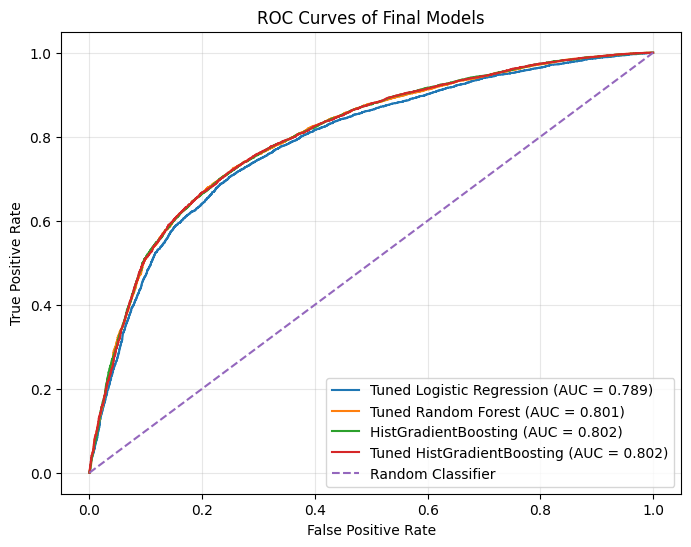

In [36]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

models = {
    "Tuned Logistic Regression": best_lr,
    "Tuned Random Forest": best_rf,
    "HistGradientBoosting": hgb,
    "Tuned HistGradientBoosting": best_hgb
}

plt.figure(figsize=(8, 6))

for name, model in models.items():

    # Use exactly the features the model was trained on
    features = model.feature_names_in_
    X_test_model = X_test[features]

    y_prob = model.predict_proba(X_test_model)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves of Final Models")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 14. Model Interpretation

Feature importance provides a way to examine which variables the tree-based models relied on most heavily when making predictions.

The feature importance analysis suggests that variables such as **age, BMI, blood pressure, height, and weight** contributed substantially to the models' predictions. These results describe which features were useful for prediction within the trained models, rather than indicating that they independently cause cardiovascular disease.

Because several variables in this dataset are correlated, particularly anthropometric measurements such as height, weight, and BMI, feature importance should not be interpreted as evidence of independent causal effects.

The analysis is therefore intended to describe **model behavior and predictive relationships**, rather than establish medical causation.



## 15. Conclusion

This project evaluated several machine learning approaches for predicting cardiovascular disease from demographic, clinical, and lifestyle features.

The workflow progressed from baseline Logistic Regression and Random Forest models to feature engineering, feature selection, hyperparameter tuning, and HistGradientBoosting. Model performance was evaluated using accuracy, precision, recall, F1 score, and ROC-AUC to capture different aspects of classification performance.

The final models achieved approximately **73% accuracy** and **0.79–0.80 ROC-AUC**, with the tree-based models showing slightly higher ROC-AUC than Logistic Regression. These results demonstrate that the available patient characteristics contain meaningful predictive information, while also showing that additional feature engineering and tuning produced relatively modest changes in overall performance.

An important limitation is that predictive performance on this dataset does not establish causal relationships or demonstrate clinical usefulness. Further work could investigate additional feature engineering, class-specific threshold selection, probability calibration, external validation, and evaluation on additional datasets.
